In [1]:
import os
import sys
import jax.nn as nn
import jax.numpy as jnp
import matplotlib.pyplot as plt

from Bio import Phylo
from io import StringIO

sys.path.append("../")

In [2]:
from modules.upgma import differentiable_upgma
from modules.upgma import get_NJ
from modules.upgma import print_matrix

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [3]:
dm = jnp.array([[  0, 1, 10, 20],
                [  1, 0,  5, 40],
                [ 10, 5,  0,  10],
                [ 20, 40, 10, 0]])
      
labels = ["Dog","Bear","Seal","Monkey"]

In [11]:
tree = differentiable_upgma(dm, [0.1,1,10], verbose = False)
print_matrix(tree,1000)

for i in range(0, tree.shape[0]):
    print("row sum  ->", tree[i].sum())

   0    0    0    0    1    0    0 
   0    0    0    0    1    0    0 
   0    0    0    0    0    1    0 
   0    0    0    0    0    0    1 
   0    0    0    0    0    1    0 
   0    0    0    0    0    0    1 
   0    0    0    0    0    0    1 
row sum  -> 0.996094
row sum  -> 1
row sum  -> 1
row sum  -> 0.996094
row sum  -> 1
row sum  -> 1
row sum  -> 1


In [12]:
# t = jnp.zeros((tree.shape[0],tree.shape[0])).astype(jnp.bfloat16)

# t_softmax = nn.softmax(tree[:-1,:]*10,axis=1)
# t = t.at[:-1,:].set(t_softmax)
# t = t.at[-1,-1].set(1) 

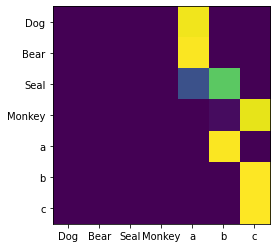

In [13]:
# create the plot
fig, ax = plt.subplots()
ax.imshow(tree.astype(jnp.float32))

# set the tick labels
ax.set_xticklabels([0,"Dog","Bear","Seal","Monkey",'a','b','c'])
ax.set_yticklabels([0,"Dog","Bear","Seal","Monkey",'a','b','c'])

plt.show()

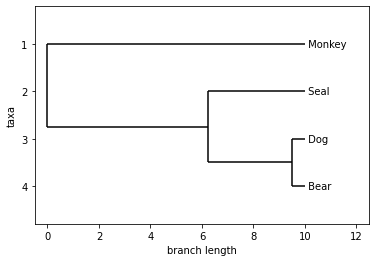

In [8]:
adj, nw = get_NJ(dm, upgma=True, nw_labels=labels)

t = Phylo.read(StringIO(nw), "newick")
Phylo.draw(t)

In [9]:
# plt.imshow(tree.astype(jnp.float32))
# plt.colorbar()

In [10]:
labels

['Dog', 'Bear', 'Seal', 'Monkey']